FICHIER jupiter  Import_donnees.ipynb

1) Extraction des données de CWRU 
2) Affichage des données 

1) Extraction des données de CWRU

In [7]:
import os
# Permet d'interagir avec le système d'exploitation.
# Exemples : parcourir des dossiers, créer des répertoires, manipuler des chemins de fichiers.
import urllib.request
from scipy.io import loadmat

url = "https://engineering.case.edu/sites/default/files/98.mat"

# r"..." (raw string) évite les problèmes avec les antislashs de Windows
dossier = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU"
os.makedirs(dossier, exist_ok=True)          # crée le dossier s'il n'existe pas
chemin = os.path.join(dossier, "98.mat")

# Téléchargement
urllib.request.urlretrieve(url, chemin)
print("Fichier enregistré dans :", chemin)

# Chargement
mat = loadmat(chemin)
print(mat.keys())

Fichier enregistré dans : C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\98.mat
dict_keys(['__header__', '__version__', '__globals__', 'X098_DE_time', 'X098_FE_time'])


2) Affichage des donnees

Roulement sans Défauts charge moteur hp=1

In [ ]:
from scipy.io import loadmat

fichier = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\98.mat"

data = loadmat(fichier)

print("type(data) :")
print(type(data))

print("data.keys() :")
print(data.keys())
#print(data.head())


type(data) :
<class 'dict'>
data.keys() :
dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


483903 échantillons, durée = 10.08 s, fr = 29.53 Hz
DE: moyenne=0.0126  RMS=0.0664  crête=0.346  facteur de crête=5.21  kurtosis=2.93
FE: moyenne=0.0324  RMS=0.0747  crête=0.322  facteur de crête=4.31  kurtosis=2.87


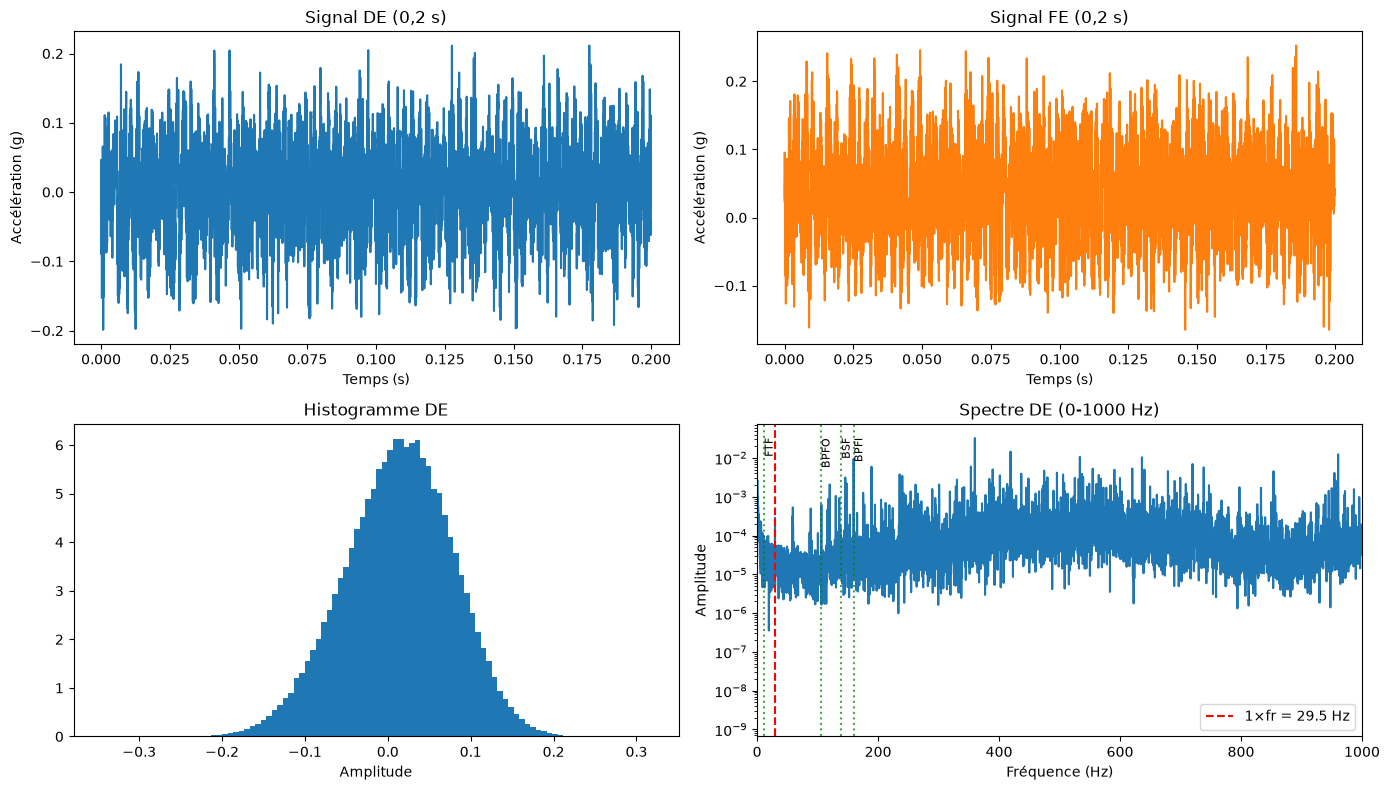

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\98.mat"
mat = loadmat(chemin)

de = mat["X098_DE_time"].ravel()      # accéléromètre côté entraînement
fe = mat["X098_FE_time"].ravel()      # accéléromètre côté ventilateur
rpm = float(np.squeeze(mat.get("X098RPM", 1772)))
fr = rpm / 60                         # fréquence de rotation de l'arbre (Hz)

fs = 48000                            # à vérifier, voir la remarque plus bas
t = np.arange(len(de)) / fs
print(f"{len(de)} échantillons, durée = {len(de)/fs:.2f} s, fr = {fr:.2f} Hz")

# Indicateurs statistiques
def indicateurs(x, nom):
    rms = np.sqrt(np.mean(x**2))
    print(f"{nom}: moyenne={x.mean():.4f}  RMS={rms:.4f}  "
          f"crête={np.abs(x).max():.3f}  facteur de crête={np.abs(x).max()/rms:.2f}  "
          f"kurtosis={kurtosis(x, fisher=False):.2f}")
indicateurs(de, "DE")
indicateurs(fe, "FE")

# Spectre (FFT avec fenêtre de Hann)
def spectre(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.abs(np.fft.rfft(x * w)) * 2 / w.sum()
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, X

f, X = spectre(de, fs)

# Fréquences caractéristiques du roulement côté entraînement (SKF 6205-2RS)
car = {"BPFO": 3.5848, "BPFI": 5.4152, "BSF": 4.7135, "FTF": 0.39828}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

n = int(0.2 * fs)  # 0,2 s de signal
ax[0, 0].plot(t[:n], de[:n]); ax[0, 0].set_title("Signal DE (0,2 s)")
ax[0, 1].plot(t[:n], fe[:n], color="tab:orange"); ax[0, 1].set_title("Signal FE (0,2 s)")
for a in ax[0]:
    a.set_xlabel("Temps (s)"); a.set_ylabel("Accélération (g)")

ax[1, 0].hist(de, bins=100, density=True)
ax[1, 0].set_title("Histogramme DE"); ax[1, 0].set_xlabel("Amplitude")

ax[1, 1].semilogy(f, X)
ax[1, 1].axvline(fr, color="r", ls="--", label=f"1×fr = {fr:.1f} Hz")
for nom, k in car.items():
    ax[1, 1].axvline(k * fr, color="g", ls=":", alpha=0.7)
    ax[1, 1].text(k * fr, X.max(), nom, rotation=90, va="top", fontsize=8)
ax[1, 1].set_xlim(0, 1000)
ax[1, 1].set_title("Spectre DE (0-1000 Hz)")
ax[1, 1].set_xlabel("Fréquence (Hz)"); ax[1, 1].set_ylabel("Amplitude"); ax[1, 1].legend()

plt.tight_layout()
plt.show()

Roulement DEFAILLANT " 110

dict_keys(['__header__', '__version__', '__globals__', 'X110_DE_time', 'X110_FE_time', 'X110RPM'])
                 DE        FE
temps (s)                    
0.000000   0.032127  0.086291
0.000021   0.078231  0.110535
0.000042   0.161468  0.110124
0.000063   0.250547  0.080127
0.000083   0.315426  0.004725
0.000104   0.311463 -0.011711
0.000125   0.233023 -0.013149
0.000146   0.115782  0.004931
0.000167  -0.011265  0.014793
0.000188  -0.112861  0.012944
                 DE        FE
temps (s)                    
10.129563 -0.121623  0.195798
10.129583 -0.128507  0.312907
10.129604 -0.088453  0.401458
10.129625 -0.028998  0.467820
10.129646  0.008553  0.525347
                  DE             FE
count  486224.000000  486224.000000
mean        0.020731       0.030707
std         0.277919       0.231544
min        -1.574212      -1.163489
25%        -0.105977      -0.120396
50%         0.022113       0.033900
75%         0.153332       0.185731
max         1.651608       0.943036
(486224

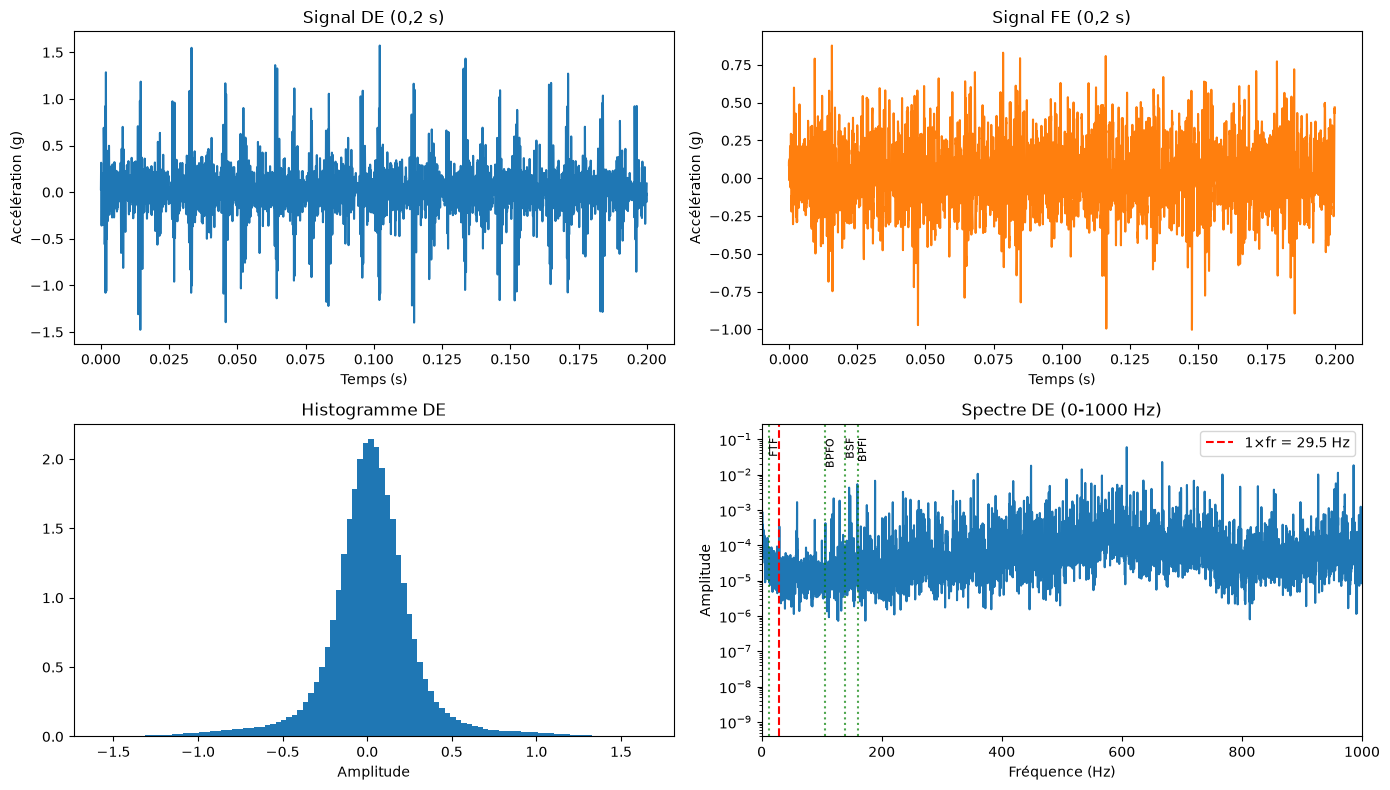

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import kurtosis

chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\110.mat"
mat = loadmat(chemin)

print(mat.keys())  # Affiche les clés du dictionnaire chargé depuis le fichier .mat


# Extrait le signal temporel de l'accéléromètre placé du côté entraînement (Drive End). 
# La fonction .ravel() l'aplatit pour obtenir un tableau à une seule dimension
de = mat["X110_DE_time"].ravel()      # accéléromètre côté entraînement

# Extrait le signal de l'accéléromètre placé du côté ventilateur (Fan End).
fe = mat["X110_FE_time"].ravel()      # accéléromètre côté ventilateur

fs = 48000                            # fréquence d'échantillonnage (Hz)

df = pd.DataFrame({
    'DE': mat['X110_DE_time'].ravel(),
    'FE': mat['X110_FE_time'].ravel()
    #'RPM': mat['X110RPM'].ravel(),  
})

df.index = df.index / fs
df.index.name = 'temps (s)'

# Supprime la limite d'affichage des lignes pour describe
pd.set_option('display.max_rows', None)

print(df.head(10))      # 10 premières lignes
print(df.tail(5))       # 5 dernières lignes
print(df.describe())# count, mean, std, min, quartiles, max
print(df.shape)         # (486224, 3)






rpm = float(np.squeeze(mat.get("X110RPM", 1772)))
fr = rpm / 60                         # fréquence de rotation de l'arbre (Hz)

fs = 48000                            # à vérifier, voir la remarque plus bas
t = np.arange(len(de)) / fs
print(f"{len(de)} échantillons, durée = {len(de)/fs:.2f} s, fr = {fr:.2f} Hz")

# Indicateurs statistiques
def indicateurs(x, nom):
    rms = np.sqrt(np.mean(x**2))
    print(f"{nom}: moyenne={x.mean():.4f}  RMS={rms:.4f}  "
          f"crête={np.abs(x).max():.3f}  facteur de crête={np.abs(x).max()/rms:.2f}  "
          f"kurtosis={kurtosis(x, fisher=False):.2f}")
indicateurs(de, "DE")
indicateurs(fe, "FE")

# Spectre (FFT avec fenêtre de Hann)
def spectre(x, fs):
    x = x - x.mean()
    w = np.hanning(len(x))
    X = np.abs(np.fft.rfft(x * w)) * 2 / w.sum()
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, X

f, X = spectre(de, fs)

# Fréquences caractéristiques du roulement côté entraînement (SKF 6205-2RS)
car = {"BPFO": 3.5848, "BPFI": 5.4152, "BSF": 4.7135, "FTF": 0.39828}

fig, ax = plt.subplots(2, 2, figsize=(14, 8))

n = int(0.2 * fs)  # 0,2 s de signal
ax[0, 0].plot(t[:n], de[:n]); ax[0, 0].set_title("Signal DE (0,2 s)")
ax[0, 1].plot(t[:n], fe[:n], color="tab:orange"); ax[0, 1].set_title("Signal FE (0,2 s)")
for a in ax[0]:
    a.set_xlabel("Temps (s)"); a.set_ylabel("Accélération (g)")

ax[1, 0].hist(de, bins=100, density=True)
ax[1, 0].set_title("Histogramme DE"); ax[1, 0].set_xlabel("Amplitude")

ax[1, 1].semilogy(f, X)
ax[1, 1].axvline(fr, color="r", ls="--", label=f"1×fr = {fr:.1f} Hz")
for nom, k in car.items():
    ax[1, 1].axvline(k * fr, color="g", ls=":", alpha=0.7)
    ax[1, 1].text(k * fr, X.max(), nom, rotation=90, va="top", fontsize=8)
ax[1, 1].set_xlim(0, 1000)
ax[1, 1].set_title("Spectre DE (0-1000 Hz)")
ax[1, 1].set_xlabel("Fréquence (Hz)"); ax[1, 1].set_ylabel("Amplitude"); ax[1, 1].legend()

plt.tight_layout()
plt.show()